<a href="https://colab.research.google.com/github/Timbo3399/INFM_SOTA2/blob/main/notebooks/workbook_timo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Data Loader (BPE, Sliding Window, Embeddings)

**Autor:** Timo · **Datum:** 10.10.2026

**Ziel:**
Write a data loader that implements
- Byte Pair Tokenization
- Sliding Window train data creation
- Token embeddings → use PyTorch nn.embedding
- Position Embeddings → use PyTorch nn.embedding
- Test it on the Data Sample

## Überblick
So wird aus Text der Input für ein Sprachmodell:

| Schritt | Beispiel |
|---|---|
| Text | `Three Rings for the` |
| Tokens (BPE) | `Three` · ` Rings` · ` for` · ` the` |
| Token-IDs | 12510, 26028, 329, 262 |
| Fenster: Input und Target | [12510, 26028, 329] und [26028, 329, 262] |
| Embedding | Jede ID wird zu einer Liste aus 256 Zahlen |

## 1. Setup
Hier oben stehen die Imports, der Tokenizer und alle Parameter. Die erste Code-Zelle gibt außerdem die Versionen von torch und tiktoken aus, damit sich das Ergebnis später reproduzieren lässt.

In [ ]:
import os
from importlib.metadata import version

import requests
import tiktoken
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

print("torch", version("torch"), "| tiktoken", version("tiktoken"))  # Versionen notieren, damit das Ergebnis reproduzierbar bleibt

tokenizer = tiktoken.get_encoding("gpt2")

torch 2.11.0+cpu | tiktoken 0.14.0


In [ ]:
# Alle Parameter stehen hier. Die Funktionen weiter unten haben bewusst keine Default-Werte.
CONFIG = {
    "data_path": "data/The-lord-of-the-rings.txt",
    "seed": 123,
    "max_length": 4,     # Fenstergröße in Tokens (Kontextlänge)
    "stride": 4,         # Schrittweite des Fensters; gleich max_length heißt, die Fenster überlappen nicht
    "batch_size": 8,
    "output_dim": 256,   # Länge eines Embedding-Vektors
}

## 2. Daten laden
Als Data Sample nehme ich *Der Herr der Ringe*, und zwar den OCR-Text von archive.org. Die Datei wird unter `data/` gespeichert. Diesen Ordner ignoriert git (er steht in der `.gitignore`), weil der Text urheberrechtlich geschützt und groß ist.

In [ ]:
file_path = CONFIG["data_path"]
os.makedirs(os.path.dirname(file_path), exist_ok=True)

if not os.path.exists(file_path):
    url = (
        "https://dn721603.ca.archive.org/0/items/"
        "tolkien-j.-the-lord-of-the-rings-harper-collins-ebooks-2010/"
        "Tolkien-J.-The-lord-of-the-rings-HarperCollins-ebooks-2010_djvu.txt"
    )
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    with open(file_path, "wb") as f:
        f.write(response.content)

In [ ]:
with open(file_path, "r", encoding="utf-8") as f:
    raw_text = f.read()
print("Anzahl Zeichen:", len(raw_text))

Anzahl Zeichen: 3073304


## 3. Byte Pair Encoding (BPE)
GPT-2 arbeitet mit Byte-Level-BPE. Das Vokabular fängt mit den 256 einzelnen Bytes an. Danach wird immer wieder das häufigste benachbarte Paar zu einem neuen Token zusammengefasst. GPT-2 hat 50.000 solcher Merges, dazu kommt das Spezial-Token `<|endoftext|>`. Das ergibt 256 + 50.000 + 1 = 50.257 Tokens.

Ein "unknown"-Token braucht man nicht, weil sich jeder Text zur Not in einzelne Bytes zerlegen lässt. Ein unbekanntes Wort wird in bekannte Teilstücke aufgeteilt, wie "Hobbitses" weiter unten.

In [ ]:
# Ohne allowed_special bricht encode ab, falls <|endoftext|> im Text steht. Das ist hier gewollt.
enc_text = tokenizer.encode(raw_text)
print("Anzahl Tokens:", len(enc_text))
assert tokenizer.decode(enc_text) == raw_text   # BPE verliert nichts: decode(encode(text)) ergibt wieder genau den Text

Anzahl Tokens: 928088


In [ ]:
n_words = len(raw_text.split())
print(f"Zeichen: {len(raw_text):,} | Wörter: {n_words:,} | Tokens: {len(enc_text):,}")
print(f"Im Schnitt {len(raw_text) / len(enc_text):.1f} Zeichen pro Token und {len(enc_text) / n_words:.2f} Tokens pro Wort")

Zeichen: 3,073,304 | Wörter: 563,767 | Tokens: 928,088
Im Schnitt 3.3 Zeichen pro Token und 1.65 Tokens pro Wort


In [ ]:
print("Vokabulargröße:", tokenizer.n_vocab)
ids = tokenizer.encode("Hobbitses sneaked into Mordor")
print(ids)
print([tokenizer.decode([i]) for i in ids])   # zeigt, in welche Teilstücke BPE die Wörter zerlegt

Vokabulargröße: 50257
[39, 672, 9895, 274, 10505, 4335, 656, 29548, 273]
['H', 'ob', 'bits', 'es', ' sne', 'aked', ' into', ' Mord', 'or']


In [ ]:
satz = "Frodo carries the One Ring to Mordor."
ids = tokenizer.encode(satz)
tokens = [tokenizer.decode([i]) for i in ids]

print(" | ".join(tokens))
pd.DataFrame({"Token": [repr(t) for t in tokens], "ID": ids})   # repr zeigt die Leerzeichen am Token-Anfang

F | ro | do |  carries |  the |  One |  Ring |  to |  Mord | or | .


,Token,ID
0,'F',37
1,'ro',305
2,'do',4598
3,' carries',10732
4,' the',262
5,' One',1881
6,' Ring',12569
7,' to',284
8,' Mord',29548
9,'or',273


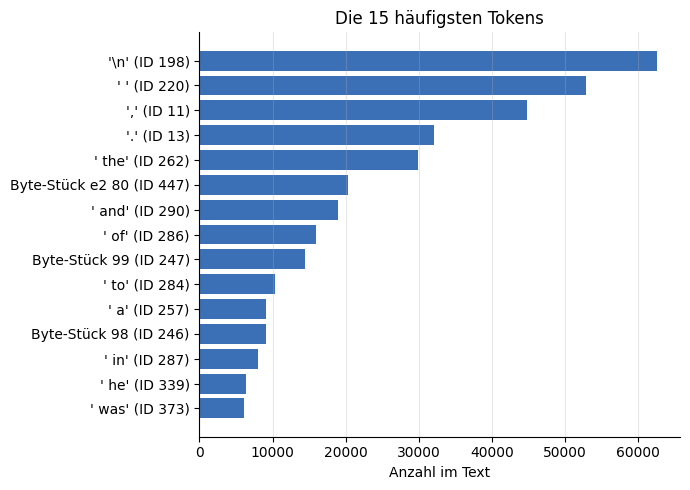

In [ ]:
def token_label(i):
    b = tokenizer.decode_single_token_bytes(i)
    try:
        return repr(b.decode("utf-8"))
    except UnicodeDecodeError:
        return f"Byte-Stück {b.hex(' ')}"   # nur ein Teil eines Sonderzeichens

top = Counter(enc_text).most_common(15)
labels = [f"{token_label(i)} (ID {i})" for i, _ in top]
counts = [c for _, c in top]
assert len(set(labels)) == len(labels), "Doppelte Beschriftungen würden Balken übereinanderlegen"

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(labels[::-1], counts[::-1], color="#3B6FB6")
ax.set_xlabel("Anzahl im Text")
ax.set_title("Die 15 häufigsten Tokens")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Die "Byte-Stücke" sind Teile der typografischen Anführungszeichen: `e2 80` + `99` ergibt ’, `e2 80` + `98` ergibt ‘. BPE zerlegt diese Zeichen in zwei Tokens. Weil der Text viele Apostrophe enthält (it’s, don’t), gehören die Stücke zu den häufigsten Tokens.

## 4. Sliding Window: die Idee
Der Input `x` ist ein Fenster aus `context_size` Tokens. Das Target `y` ist dasselbe Fenster, nur um ein Token nach rechts verschoben. An jeder Position soll das Modell also das nächste Token vorhersagen.

In [ ]:
enc_sample = enc_text[50:]   # die ersten 50 Tokens sind OCR-Reste (ARDS ASIN ...), die lasse ich für die Demo weg
context_size = 4

x = enc_sample[:context_size]
y = enc_sample[1:context_size + 1]
print("x:", x)
print("y:", y)
assert x[1:] == y[:-1]   # y ist x, um ein Token verschoben

for i in range(1, context_size + 1):
    print(tokenizer.decode(enc_sample[:i]), "--->", tokenizer.decode([enc_sample[i]]))

x: [198, 12510, 26028, 329]
y: [12510, 26028, 329, 262]

 ---> Three

Three --->  Rings

Three Rings --->  for

Three Rings for --->  the


In [ ]:
def fenster_tabelle(token_ids, max_length, stride, n):
    assert (n - 1) * stride + max_length + 1 <= len(token_ids), "Satz zu kurz für so viele Fenster"
    return pd.DataFrame([
        {"Start": i,
         "Input": tokenizer.decode(token_ids[i:i + max_length]),
         "Target": tokenizer.decode(token_ids[i + 1:i + max_length + 1])}
        for i in range(0, n * stride, stride)
    ])

satz_ids = tokenizer.encode("The hobbits left the Shire at night and walked east towards the misty mountains.")
print("stride = 1 (Fenster überlappen):")
display(fenster_tabelle(satz_ids, max_length=4, stride=1, n=4))
print("stride = 4 (Fenster liegen hintereinander):")
display(fenster_tabelle(satz_ids, max_length=4, stride=4, n=3))

stride = 1 (Fenster überlappen):


,Start,Input,Target
0,0,The hobbits left,hobbits left the
1,1,hobbits left the,bits left the Sh
2,2,bits left the Sh,left the Shire
3,3,left the Shire,the Shire at


stride = 4 (Fenster liegen hintereinander):


,Start,Input,Target
0,0,The hobbits left,hobbits left the
1,4,the Shire at,Shire at night
2,8,night and walked east,and walked east towards


## 5. Dataset und DataLoader
`SlidingWindowDataset` schiebt ein Fenster der Länge `max_length` in Schritten von `stride` über den ganzen Text und speichert zu jedem Fenster das Paar aus Input und Target. Ist `stride` gleich `max_length`, überlappen sich die Fenster nicht, bei kleinerem `stride` schon. Der `DataLoader` packt die Paare dann in Batches.

In [ ]:
class SlidingWindowDataset(Dataset):
    """Zerlegt einen Text in Fenster aus Input und Target. Das Target ist der Input, um ein Token verschoben."""

    def __init__(self, txt, tokenizer, max_length, stride):
        token_ids = tokenizer.encode(txt)
        assert len(token_ids) > max_length, (
            f"Text hat nur {len(token_ids)} Tokens, braucht > max_length={max_length}")

        self.input_ids, self.target_ids = [], []
        for i in range(0, len(token_ids) - max_length, stride):
            self.input_ids.append(torch.tensor(token_ids[i:i + max_length]))
            self.target_ids.append(torch.tensor(token_ids[i + 1:i + max_length + 1]))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [ ]:
def create_dataloader(txt, tokenizer, batch_size, max_length, stride, shuffle, seed):
    dataset = SlidingWindowDataset(txt, tokenizer, max_length, stride)
    assert len(dataset) >= batch_size, f"Nur {len(dataset)} Fenster für batch_size={batch_size}"
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=True,                                   # unvollständigen letzten Batch verwerfen, damit alle gleich groß sind
        generator=torch.Generator().manual_seed(seed),    # fester Seed, damit das Mischen bei jedem Lauf gleich ist
    )

## 6. Test des DataLoaders
Zuerst teste ich einen kleinen Ausschnitt mit `stride=1`. Daran sieht man gut, wie das Fenster jedes Mal ein Token weiterrutscht. Danach läuft der ganze Text mit den Werten aus `CONFIG`.

Achtung: `stride=1` auf dem ganzen Text mit großem `max_length` füllt den RAM sehr schnell.

In [ ]:
demo_loader = create_dataloader(raw_text[:5_000], tokenizer, batch_size=1,
                                max_length=4, stride=1, shuffle=False, seed=CONFIG["seed"])
it = iter(demo_loader)
(x1, y1), (x2, y2) = next(it), next(it)
print(x1, y1)
print(x2, y2)
assert torch.equal(x1[0, 1:], x2[0, :-1])   # bei stride=1 rückt das zweite Fenster genau ein Token weiter

tensor([[48294,  7054,  1268,   327]]) tensor([[7054, 1268,  327, 5868]])
tensor([[7054, 1268,  327, 5868]]) tensor([[ 1268,   327,  5868, 12964]])


In [ ]:
dataloader = create_dataloader(raw_text, tokenizer, CONFIG["batch_size"], CONFIG["max_length"],
                               CONFIG["stride"], shuffle=False, seed=CONFIG["seed"])
inputs, targets = next(iter(dataloader))
print("Anzahl Batches:", len(dataloader))
print(inputs)
print(targets)
assert inputs.shape == (CONFIG["batch_size"], CONFIG["max_length"])
assert torch.equal(inputs[:, 1:], targets[:, :-1])

Anzahl Batches: 29002
tensor([[48294,  7054,  1268,   327],
        [ 5868, 12964,  4805,  1268],
        [ 6242,  2390,    33,  3861],
        [   36,   220,   628,   198],
        [   50,   220,   628,   198],
        [  464,  4453,   286,   262],
        [26028,   220,   628,   198],
        [17513,   220,   628,   198]])
tensor([[ 7054,  1268,   327,  5868],
        [12964,  4805,  1268,  6242],
        [ 2390,    33,  3861,    36],
        [  220,   628,   198,    50],
        [  220,   628,   198,   464],
        [ 4453,   286,   262, 26028],
        [  220,   628,   198, 17513],
        [  220,   628,   198,    41]])


## 7. Embeddings
`nn.Embedding(n, d)` ist eine trainierbare Matrix mit n Zeilen und d Spalten. Jede ID wählt einfach ihre Zeile aus. Das ist ein Lookup und rechnerisch dasselbe wie ein One-Hot-Vektor mal die Gewichtsmatrix.

Das Token Embedding hat eine Zeile pro Token-ID, also 50.257 Zeilen. Das Position Embedding hat eine Zeile pro Position im Fenster, also `max_length` Zeilen. Das Input Embedding ist die Summe aus beiden.

In [ ]:
torch.manual_seed(CONFIG["seed"])
mini = nn.Embedding(6, 3)                       # 6 IDs, jede bekommt einen Vektor mit 3 Werten
idx = torch.tensor([3])
print(mini.weight)
print(mini(idx))
assert torch.equal(mini(idx)[0], mini.weight[3])                      # das Embedding für ID 3 ist einfach Zeile 3 der Matrix
one_hot = nn.functional.one_hot(idx, num_classes=6).float()
assert torch.allclose(one_hot @ mini.weight, mini(idx))               # und dasselbe wie One-Hot-Vektor mal Gewichtsmatrix

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)
tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [ ]:
vocab_size = tokenizer.n_vocab   # vom Tokenizer übernehmen statt 50257 fest reinzuschreiben
torch.manual_seed(CONFIG["seed"])
token_embedding_layer = nn.Embedding(vocab_size, CONFIG["output_dim"])
token_embeddings = token_embedding_layer(inputs)
print("Token Embeddings:", token_embeddings.shape)
assert token_embeddings.shape == (CONFIG["batch_size"], CONFIG["max_length"], CONFIG["output_dim"])

Token Embeddings: torch.Size([8, 4, 256])


In [ ]:
context_length = CONFIG["max_length"]   # eine Zeile pro Position im Fenster
pos_embedding_layer = nn.Embedding(context_length, CONFIG["output_dim"])
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
print("Position Embeddings:", pos_embeddings.shape)
assert pos_embeddings.shape == (context_length, CONFIG["output_dim"])

Position Embeddings: torch.Size([4, 256])


In [ ]:
# [8, 4, 256] + [4, 256]: PyTorch addiert die Position Embeddings per Broadcasting zu jedem Eintrag im Batch
input_embeddings = token_embeddings + pos_embeddings
assert input_embeddings.shape == token_embeddings.shape
print("Input Embeddings:", input_embeddings.shape)

Input Embeddings: torch.Size([8, 4, 256])


In [ ]:
demo_ids = torch.tensor([tokenizer.encode("in the end the")])   # ' the' steht an Position 1 und 3
assert demo_ids.shape[1] == context_length

tok = token_embedding_layer(demo_ids)[0]
inp = tok + pos_embeddings

assert torch.equal(tok[1], tok[3])        # gleiches Token, also gleiches Token Embedding
assert not torch.equal(inp[1], inp[3])    # andere Position, also anderes Input Embedding
print("' the' an Position 1 und 3: Token Embedding gleich, Input Embedding verschieden")

' the' an Position 1 und 3: Token Embedding gleich, Input Embedding verschieden


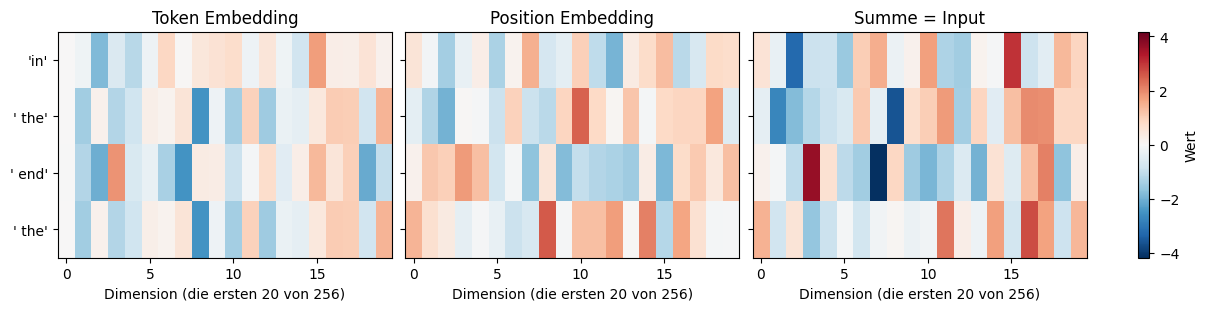

In [ ]:
daten = {"Token Embedding": tok, "Position Embedding": pos_embeddings, "Summe = Input": inp}
vmax = max(d[:, :20].abs().max().item() for d in daten.values())   # gleiche Skala für alle drei Bilder

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True, layout="constrained")
for ax, (titel, d) in zip(axes, daten.items()):
    im = ax.imshow(d[:, :20].detach(), cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_title(titel)
    ax.set_xlabel("Dimension (die ersten 20 von 256)")
    ax.set_xticks(range(0, 20, 5))
axes[0].set_yticks(range(context_length), [repr(tokenizer.decode([i])) for i in demo_ids[0].tolist()])
fig.colorbar(im, ax=axes, label="Wert")
plt.show()

Wichtig: Die Zahlen in den Embeddings sind noch zufällig, weil nichts trainiert wurde. Die Muster in der Heatmap bedeuten also nichts. Man sieht nur, dass die beiden " the"-Zeilen im Token Embedding gleich sind und nach dem Addieren der Position nicht mehr.

In [ ]:
import ipywidgets as widgets
_ = widgets.interact(lambda text: print(" | ".join(tokenizer.decode([i]) for i in tokenizer.encode(text))),
                     text="Gandalf the Grey")

interactive(children=(Text(value='Gandalf the Grey', description='text'), Output()), _dom_classes=('widget-int…

## 8. Fazit

### Warum ist `y` um ein Token verschoben?
Das Modell lernt Next-Token-Prediction. An Position i soll es Token i+1 vorhersagen, und ein einziges Fenster liefert dadurch gleich `max_length` Trainingsbeispiele.

### Was macht `stride`?
Bei `stride = max_length` liegen die Fenster direkt hintereinander und jedes Token ist genau einmal Input. Das gibt weniger Samples, aber keine doppelten. Mit `stride < max_length` überlappen sich die Fenster. Dann gibt es mehr Samples (bei `stride=1` fast so viele wie Tokens), dafür viel Redundanz und mehr RAM-Verbrauch.

### Warum ist die Token-Embedding-Matrix 50.257 × 256 groß?
Jede Token-ID aus dem GPT-2-Vokabular bekommt eine Zeile. Die 256 ist `output_dim`, also die Länge jedes Vektors, und die habe ich selbst gewählt. Am Anfang sind die Werte zufällig, gelernt werden sie erst im Training.

### Was würde ohne Position Embeddings fehlen?
Das Token Embedding hängt nur von der ID ab, die Position spielt dabei keine Rolle. Self-Attention im späteren Transformer erkennt die Reihenfolge der Tokens nicht von selbst. "Hund beißt Mann" und "Mann beißt Hund" wären für das Modell dann nicht zu unterscheiden.

### Beobachtung zu den Daten
Der OCR-Text hat am Anfang einen Header, und viele Fenster bestehen nur aus Leerzeichen und Zeilenumbrüchen (Token 220, 628 und 198). Für Task 1 stört das nicht. Ob wir den Text vor dem Training bereinigen, entscheiden wir im Team.